Shots: 100
Counts: {'0': 53, '1': 47}
P(0): 0.53
P(1): 0.47
----------------------------------------
Shots: 1000
Counts: {'0': 506, '1': 494}
P(0): 0.506
P(1): 0.494
----------------------------------------
Shots: 10000
Counts: {'0': 5034, '1': 4966}
P(0): 0.5034
P(1): 0.4966
----------------------------------------


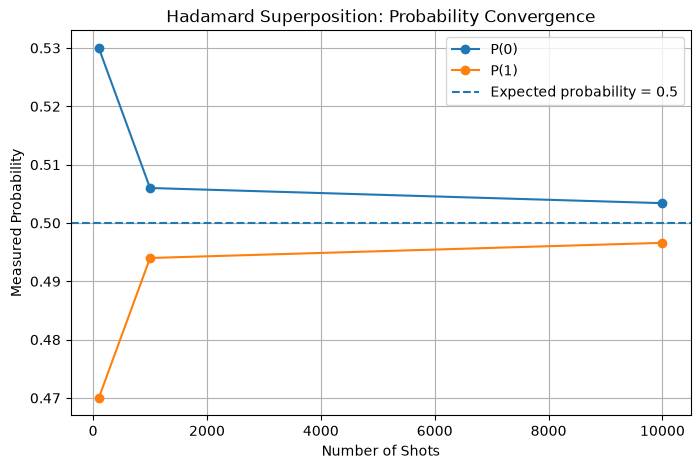

In [15]:
#EASY

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

simulator = AerSimulator()

shots_list = [100, 1000, 10000]

prob_0 = []
prob_1 = []

for shots in shots_list:

    # Create circuit
    qc = QuantumCircuit(1, 1)

    # Create |+> state
    qc.h(0)

    # Measure
    qc.measure(0, 0)

    # Run
    result = simulator.run(qc, shots=shots).result()

    counts = result.get_counts()

    zeros = counts.get('0', 0)
    ones = counts.get('1', 0)

    p0 = zeros / shots
    p1 = ones / shots

    prob_0.append(p0)
    prob_1.append(p1)

    print("Shots:", shots)
    print("Counts:", counts)
    print("P(0):", p0)
    print("P(1):", p1)
    print("-" * 40)


# -----------------------------
# Graph
# -----------------------------

plt.figure(figsize=(8, 5))

plt.plot(shots_list, prob_0, marker='o', label='P(0)')
plt.plot(shots_list, prob_1, marker='o', label='P(1)')

plt.axhline(
    y=0.5,
    linestyle='--',
    label='Expected probability = 0.5'
)

plt.xlabel("Number of Shots")
plt.ylabel("Measured Probability")
plt.title("Hadamard Superposition: Probability Convergence")

plt.legend()
plt.grid(True)

plt.show()

|+> state:
{'0': 1000}

|-> state:
{'0': 1000}


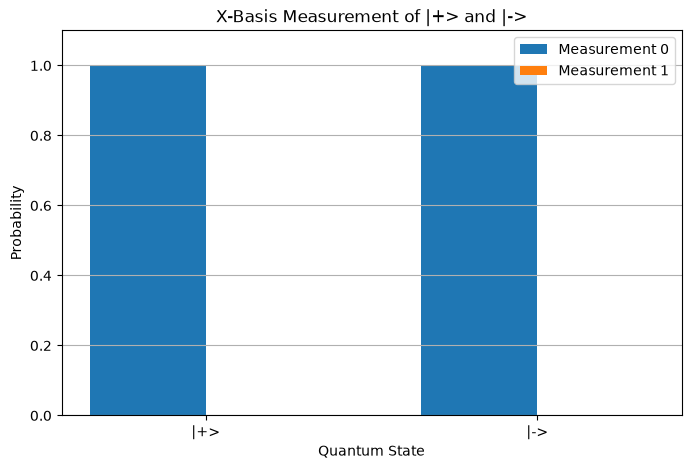

In [16]:
#MEDIUM

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

simulator = AerSimulator()

shots = 1000

# ==================================
# |+> STATE
# ==================================

qc_plus = QuantumCircuit(1, 1)

# Prepare |+>
qc_plus.h(0)

# Convert X basis to computational basis
qc_plus.h(0)

# Measure
qc_plus.measure(0, 0)

result_plus = simulator.run(
    qc_plus,
    shots=shots
).result()

counts_plus = result_plus.get_counts()

plus_0 = counts_plus.get('0', 0)
plus_1 = counts_plus.get('1', 0)


# ==================================
# |-> STATE
# ==================================

qc_minus = QuantumCircuit(1, 1)

# Prepare |->
qc_minus.h(0)
qc_minus.x(0)

# Convert X basis to computational basis
qc_minus.h(0)

# Measure
qc_minus.measure(0, 0)

result_minus = simulator.run(
    qc_minus,
    shots=shots
).result()

counts_minus = result_minus.get_counts()

minus_0 = counts_minus.get('0', 0)
minus_1 = counts_minus.get('1', 0)


# ==================================
# Print Results
# ==================================

print("|+> state:")
print(counts_plus)

print("\n|-> state:")
print(counts_minus)


# ==================================
# Graph
# ==================================

states = ['|+>', '|->']

probability_0 = [
    plus_0 / shots,
    minus_0 / shots
]

probability_1 = [
    plus_1 / shots,
    minus_1 / shots
]

x = range(len(states))

plt.figure(figsize=(8, 5))

width = 0.35

plt.bar(
    [i - width/2 for i in x],
    probability_0,
    width,
    label='Measurement 0'
)

plt.bar(
    [i + width/2 for i in x],
    probability_1,
    width,
    label='Measurement 1'
)

plt.xticks(x, states)

plt.xlabel("Quantum State")
plt.ylabel("Probability")
plt.title("X-Basis Measurement of |+> and |->")

plt.ylim(0, 1.1)

plt.legend()
plt.grid(axis='y')

plt.show()

In [18]:
#HARD

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()
qc1 = QuantumCircuit(2, 2)
qc1.h(0)
qc1.cx(0, 1)
qc1.measure(0, 0)
qc1.measure(1, 1)

result1 = simulator.run(
    qc1,
    shots=1000
).result()

counts1 = result1.get_counts()

print("Bell pair measurement:")
print(counts1)

Bell pair measurement:
{'11': 483, '00': 517}


In [13]:
#REAL WORLD

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import math

simulator = AerSimulator()
true_theta = math.pi / 3
shots = 10000

qc = QuantumCircuit(1, 1)
qc.ry(true_theta, 0)
qc.measure(0, 0)

result = simulator.run(
    qc,
    shots=shots
).result()

counts = result.get_counts()
ones = counts.get('1', 0)
p1 = ones / shots
estimated_theta = 2 * math.asin(math.sqrt(p1))

print("True angle:")
print(true_theta)
print("\nMeasurement counts:")
print(counts)
print("\nEstimated P(1):")
print(p1)
print("\nEstimated angle:")
print(estimated_theta)
print("\nTrue angle in degrees:")
print(math.degrees(true_theta))
print("\nEstimated angle in degrees:")
print(math.degrees(estimated_theta))

True angle:
1.0471975511965976

Measurement counts:
{'0': 7556, '1': 2444}

Estimated P(1):
0.2444

Estimated angle:
1.0342158927023175

True angle in degrees:
59.99999999999999

Estimated angle in degrees:
59.25620575719759


Quantum Random Generator:
{'1': 548, '0': 452}
Quantum p-value: 0.0026455298391442005

Biased Classical Generator:
0: 408
1: 592
Classical p-value: 6.520546720192982e-09

Interpretation:
Quantum generator appears biased.
Classical generator is significantly biased.


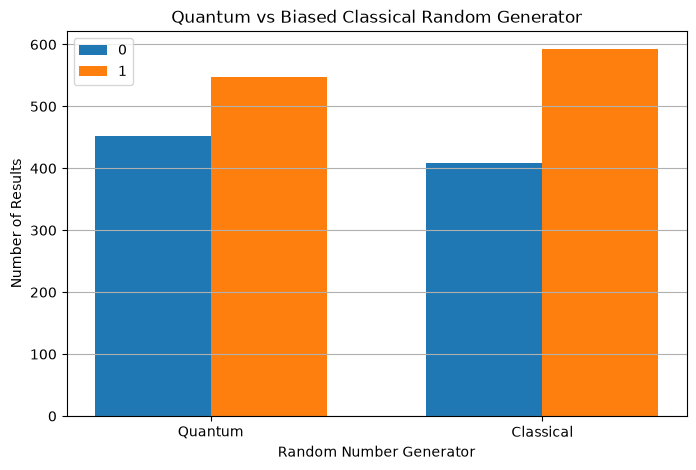

In [19]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from scipy.stats import binomtest
import random

shots = 1000
simulator = AerSimulator()
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)

result = simulator.run(
    qc,
    shots=shots
).result()

quantum_counts = result.get_counts()

quantum_ones = quantum_counts.get('1', 0)

print("Quantum counts:")
print(quantum_counts)

quantum_test = binomtest(
    quantum_ones,
    shots,
    p=0.5
)

print("\nQuantum p-value:")
print(quantum_test.pvalue)

classical_data = []
for i in range(shots):
    value = 1 if random.random() < 0.60 else 0
    classical_data.append(value)
classical_ones = sum(classical_data)

print("\nClassical biased generator:")
print("Number of 1s:", classical_ones)

classical_test = binomtest(
    classical_ones,
    shots,
    p=0.5
)

print("\nClassical p-value:")
print(classical_test.pvalue)

alpha = 0.05
print("\n--- Interpretation ---")

if quantum_test.pvalue < alpha:
    print("Quantum generator appears significantly biased.")
else:
    print("Quantum generator is consistent with a fair random source.")

if classical_test.pvalue < alpha:
    print("Classical generator is significantly biased.")
else:
    print("Classical generator appears fair.")